In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from google.colab import files

uploaded = files.upload()

Saving customer_churn_training_dataset.csv to customer_churn_training_dataset.csv


In [3]:
df = pd.read_csv("/content/customer_churn_training_dataset.csv")

In [4]:
df

,Tenure_Months,Monthly_Charges,Support_Calls,Late_Payments,Contract_Type,Usage_Hours_Per_Month,Add_On_Services,Churn
0,7,1349.51,2,0,0,37.6,0,0
1,56,1974.15,3,0,0,27.6,1,0
2,48,2286.32,1,0,0,46.0,0,0
3,32,1884.53,0,0,2,34.6,0,0
4,32,2418.06,0,0,1,23.9,2,0
...,...,...,...,...,...,...,...,...
1195,46,948.04,1,1,1,34.8,0,0
1196,52,1550.43,1,0,2,11.3,4,0
1197,71,936.64,1,1,0,26.8,4,0
1198,58,1518.43,0,0,1,16.4,4,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Tenure_Months          1200 non-null   int64  
 1   Monthly_Charges        1200 non-null   float64
 2   Support_Calls          1200 non-null   int64  
 3   Late_Payments          1200 non-null   int64  
 4   Contract_Type          1200 non-null   int64  
 5   Usage_Hours_Per_Month  1200 non-null   float64
 6   Add_On_Services        1200 non-null   int64  
 7   Churn                  1200 non-null   int64  
dtypes: float64(2), int64(6)
memory usage: 75.1 KB


In [6]:
df.describe()

,Tenure_Months,Monthly_Charges,Support_Calls,Late_Payments,Contract_Type,Usage_Hours_Per_Month,Add_On_Services,Churn
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.823333,1411.427042,1.365000,0.653333,0.721667,28.017250,1.953333,0.294167
std,20.712548,643.575514,1.197067,0.812633,0.766825,9.788011,1.419331,0.455857
min,1.000000,300.140000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
25%,19.000000,840.245000,0.000000,0.000000,0.000000,21.700000,1.000000,0.000000
50%,37.000000,1385.785000,1.000000,0.000000,1.000000,28.000000,2.000000,0.000000
75%,55.000000,1998.500000,2.000000,1.000000,1.000000,34.500000,3.000000,1.000000
max,72.000000,2497.730000,7.000000,5.000000,2.000000,65.000000,4.000000,1.000000


In [7]:
df.isnull().sum()

,0
Tenure_Months,0
Monthly_Charges,0
Support_Calls,0
Late_Payments,0
Contract_Type,0
Usage_Hours_Per_Month,0
Add_On_Services,0
Churn,0


In [8]:
df["Churn"].value_counts()

,count
Churn,
0,847
1,353


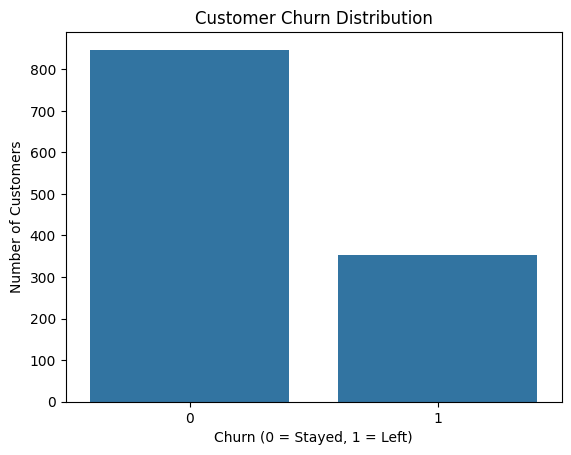

In [9]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")

plt.show()

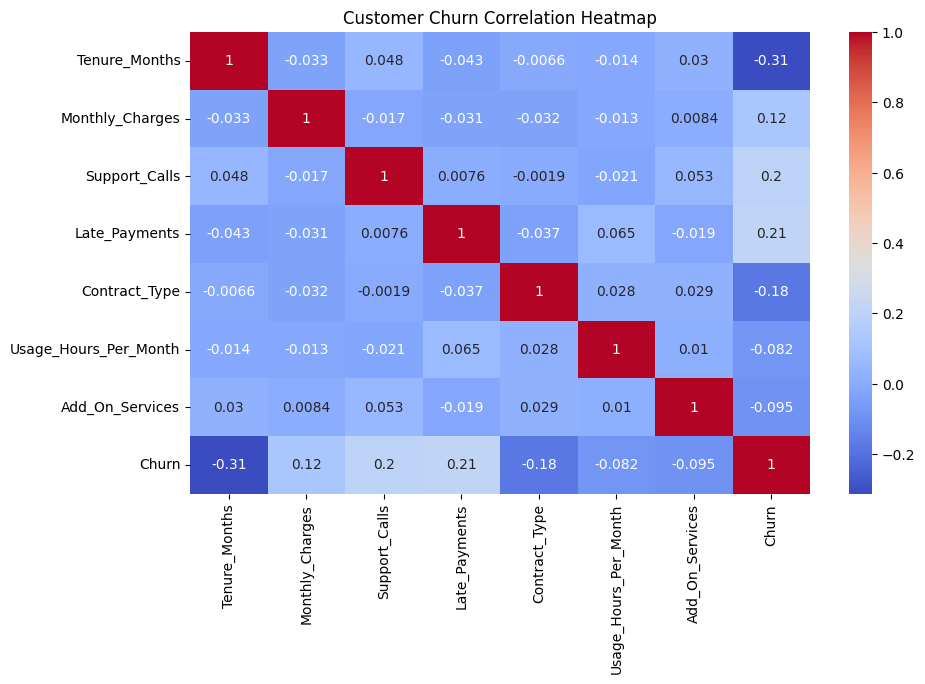

In [10]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Customer Churn Correlation Heatmap")
plt.show()

In [11]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (960, 7)
Testing data: (240, 7)


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [14]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(max_iter=1000))
])

In [15]:
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic', LogisticRegression(max_iter=1000))])

In [16]:
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('logistic', LogisticRegression(max_iter=1000))])

In [17]:
y_pred = model.predict(X_test)

In [18]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.7541666666666667
Model Accuracy Percentage: 75.41666666666667 %


In [19]:
from sklearn.metrics import recall_score, f1_score

recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Recall Score:", recall)
print("F1 Score:", f1)

Recall Score: 0.39436619718309857
F1 Score: 0.48695652173913045


In [20]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.78      0.91      0.84       169
           1       0.64      0.39      0.49        71

    accuracy                           0.75       240
   macro avg       0.71      0.65      0.66       240
weighted avg       0.74      0.75      0.73       240



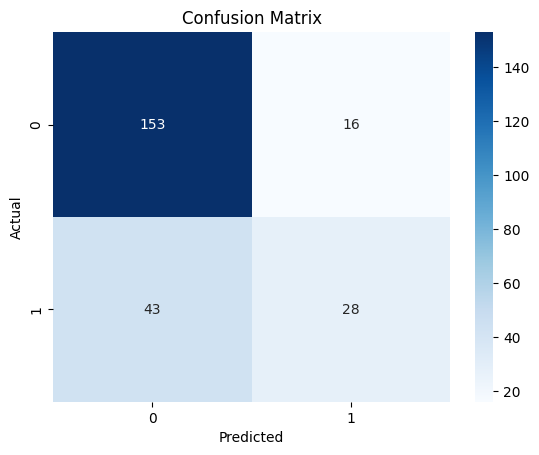

In [21]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [22]:
import joblib

joblib.dump(model, "customer_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [23]:
app_code = '''
import streamlit as st
import pandas as pd
import joblib

model = joblib.load("customer_churn_model.pkl")

st.set_page_config(
    page_title="Customer Churn Predictor",
    page_icon="📊",
    layout="centered"
)

st.title("📊 Customer Churn Prediction System")

st.write(
    "Enter customer information to predict "
    "whether the customer is likely to leave."
)

st.divider()

st.subheader("Customer Information")

col1, col2 = st.columns(2)

with col1:
    tenure = st.number_input(
        "Tenure (Months)", 1, 100, 12
    )

    monthly_charges = st.number_input(
        "Monthly Charges (₹)", 0.0, 10000.0, 999.0
    )

    support_calls = st.number_input(
        "Support Calls", 0, 20, 2
    )

    late_payments = st.number_input(
        "Late Payments", 0, 20, 1
    )

with col2:
    contract = st.selectbox(
        "Contract Type",
        ["Monthly", "Annual", "Two-year"]
    )

    usage_hours = st.number_input(
        "Usage Hours Per Month", 0.0, 200.0, 30.0
    )

    add_on_services = st.number_input(
        "Add-on Services", 0, 10, 2
    )

contract_mapping = {
    "Monthly": 0,
    "Annual": 1,
    "Two-year": 2
}

if st.button("Predict Customer Churn"):

    features = pd.DataFrame([{
        "Tenure_Months": tenure,
        "Monthly_Charges": monthly_charges,
        "Support_Calls": support_calls,
        "Late_Payments": late_payments,
        "Contract_Type": contract_mapping[contract],
        "Usage_Hours_Per_Month": usage_hours,
        "Add_On_Services": add_on_services
    }])

    prediction = model.predict(features)[0]

    probability = model.predict_proba(features)[0][1]

    st.divider()

    if prediction == 1:

        st.error("⚠️ Customer is likely to leave!")

        st.write(
            f"Estimated churn probability: {probability:.2%}"
        )

        st.info(
            "Suggested action: Contact the customer "
            "and review their service experience."
        )

    else:

        st.success("✅ Customer is likely to stay!")

        st.write(
            f"Estimated retention probability: "
            f"{(1-probability):.2%}"
        )
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py created successfully!")

app.py created successfully!


In [24]:
requirements = """
streamlit
pandas
scikit-learn
joblib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [25]:
from google.colab import files

files.download("app.py")
files.download("requirements.txt")
files.download("customer_churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>